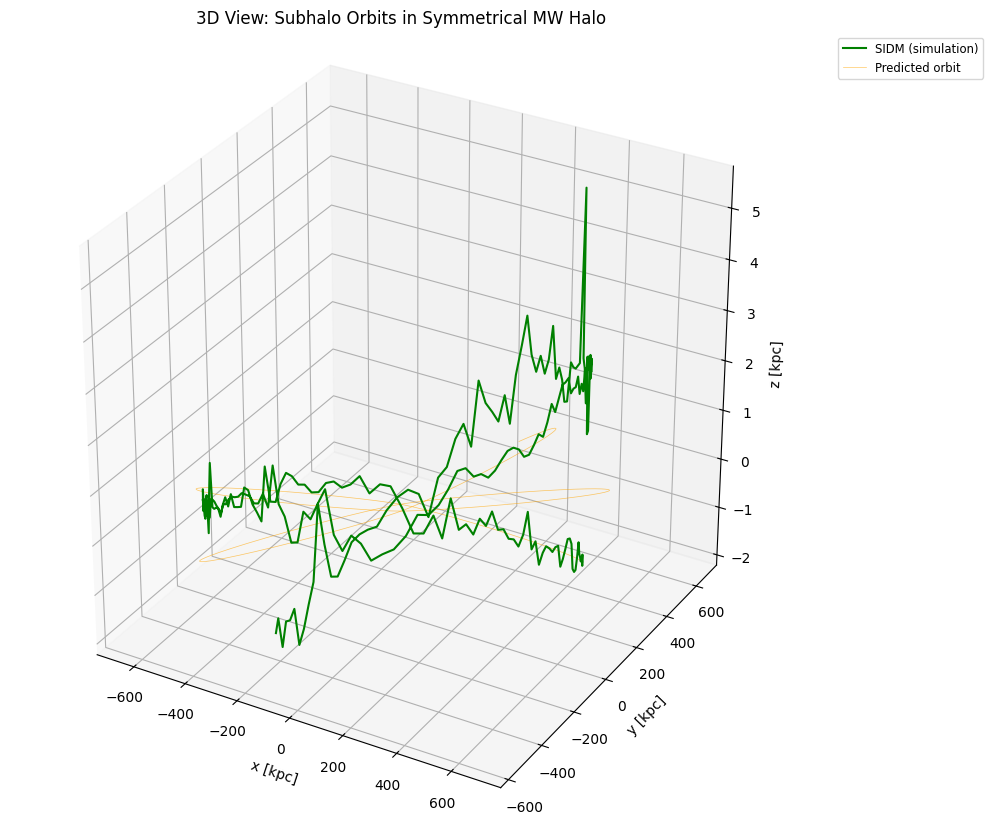

In [10]:
#!/usr/bin/env python3
"""
3D Subhalo Orbit in NFW Host (prediction vs AHF data)
"""

import os
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from galpy.potential import NFWPotential
from galpy.orbit import Orbit

# =======================================================
# HELPER FUNCTIONS
# =======================================================

def get_valid_snapshots(data_path, total_snapshots):
    valid_snapshots = []
    for i in range(total_snapshots + 1):
        filepath = f"{data_path}{i}-halos"
        if os.path.exists(filepath):
            try:
                with open(filepath, "r") as f:
                    lines = f.readlines()
                    if len(lines) > 1:
                        valid_snapshots.append(i)
            except Exception:
                continue
    return valid_snapshots

def load_ahf_dataset(data_path, total_snapshots, host_center):
    valid = get_valid_snapshots(data_path, total_snapshots)
    if not valid:
        raise RuntimeError(f"No valid snapshot files found in {data_path}")
    centers, snaps, dists = load_subhalo_centers_from_ahf(data_path, valid, host_center)
    
    # SHIFT TO ORIGIN
    centers_relative = centers - host_center
    
    return {
        "path": data_path,
        "valid_snapshots": np.array(valid),
        "centers": centers_relative,
        "snapshots": snaps,
        "orbital_dist": dists,
    }

def load_subhalo_centers_from_ahf(data_path, snapshot_list, host_center):
    centers, snapshots, orbital_dist = [], [], []
    for snap in snapshot_list:
        filepath = f"{data_path}{snap}-halos"
        with open(filepath, "r") as file:
            next(file)
            first_line = None
            for line in file:
                if line.strip():
                    first_line = line
                    break
            if first_line is None: continue
            tokens = first_line.strip().split()
            Xc, Yc, Zc = float(tokens[5]), float(tokens[6]), float(tokens[7])
            centers.append([Xc, Yc, Zc])
            snapshots.append(snap)
            orbital_dist.append(np.linalg.norm(np.array([Xc, Yc, Zc]) - host_center))
    return np.array(centers), np.array(snapshots), np.array(orbital_dist)

def compute_predicted_orbit_positions():
    pot = NFWPotential(mvir=M_VIR_1E12, conc=C_HOST, ro=RO, vo=VO)
    orb = Orbit(vxvv=[R0_KPC/RO_KPC, vR0_KMS/VO_KMS, vT0_KMS/VO_KMS, z0_KPC/RO_KPC, vz0_KMS/VO_KMS, phi0_RAD], ro=RO, vo=VO)
    tmax_galpy = T_MAX_GYR / T_UNIT_GYR
    t_galpy = np.linspace(0.0, tmax_galpy, N_STEPS)
    orb.integrate(t_galpy, pot)
    return (orb.x(t_galpy)*RO_KPC, 
            orb.y(t_galpy)*RO_KPC, 
            orb.z(t_galpy)*RO_KPC)

# ==================== CONFIGURATION ====================

AHF_DATASETS = [
    {"name": "SIDM", "path": "./Data/subhalo_evp_3_1_1/AHFout/", "color": "green"}
]

TOTAL_SNAPSHOTS = 280
HOST_CENTER = np.array([1e4, 1e4, 1e4])  
MVIR_MSUN = 2*(10**13.5)
M_VIR_1E12 = MVIR_MSUN / (10**12.0)
C_HOST = 6.5
RO, VO = 1.0, 220.0
RO_KPC, VO_KMS = 1.0, 220.0
T_UNIT_GYR = RO_KPC / (VO_KMS * 1.022712)

R0_KPC, z0_KPC, phi0_RAD = 0.7*974.407, 0.0, 0.0
vR0_KMS, vT0_KMS, vz0_KMS = 0.0, 33.1515, 0.0
T_MAX_GYR, N_STEPS = 14.0, 2001

ORIGIN = np.array([1e4, 1e4, 1e4])

# ================================
# MAIN
# ================================

ahf_runs = [load_ahf_dataset(ds["path"], TOTAL_SNAPSHOTS, HOST_CENTER) for ds in AHF_DATASETS]
for i, ds in enumerate(AHF_DATASETS): 
    ahf_runs[i]["name"], ahf_runs[i]["color"] = ds["name"], ds["color"]

try:
    x_pred, y_pred, z_pred = compute_predicted_orbit_positions()
    have_predicted = True
except Exception as e:
    print(f"Warning: {e}"); have_predicted = False

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection="3d")

linestyles = ['-', '--', '-.', ':']

# PLOT AHF TRAJECTORIES
for i, run in enumerate(ahf_runs):
    x, y, z = run["centers"][:,0], run["centers"][:,1], run["centers"][:,2]
    ax.plot(x, y, z, linewidth=1.5, linestyle=linestyles[i % 4], color=run["color"], 
            label=f'{run["name"]} (simulation)', alpha=1.0, zorder=10)

# PLOT PREDICTION
if have_predicted:
    ax.plot(x_pred, y_pred, z_pred, color="orange", linewidth=0.5, label="Predicted orbit", alpha=0.6, zorder=5)

# Force the aspect ratio to be equal for symmetry
ax.set_box_aspect([1, 1, 1]) 

ax.set_xlabel("x [kpc]"); ax.set_ylabel("y [kpc]"); ax.set_zlabel("z [kpc]")
ax.set_title("3D View: Subhalo Orbits in Symmetrical MW Halo")
ax.legend(loc="upper left", bbox_to_anchor=(1.05, 1), fontsize='small', framealpha=0.8)

plt.tight_layout()
plt.show()

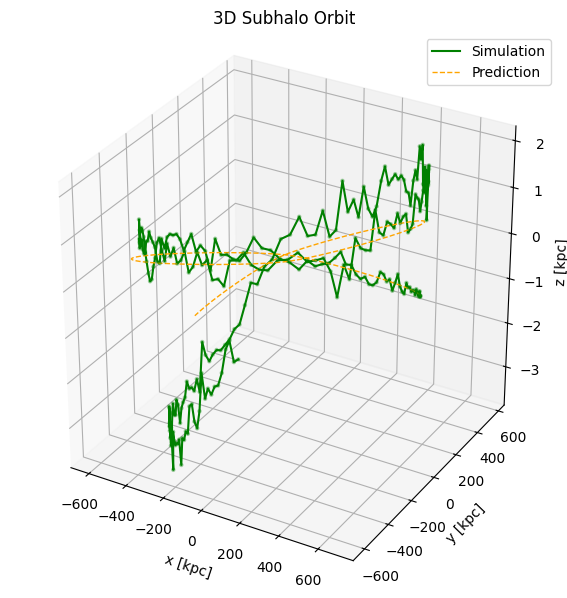

In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
from galpy.potential import NFWPotential
from galpy.orbit import Orbit

# ==================== CONFIG & CONSTANTS ====================
# AHF_PATH = "./Data/subhalo_evp_3_1_1/AHFout/"
# AHF_PATH = "./Data/SIDM_AHFout/"
AHF_PATH = "./Data/CDM_AHFout/"
TOTAL_SNAPS = 280
HOST_CENTER = np.array([10000.0, 10000.0, 10000.0])

# Galpy Params
RO_KPC, VO_KMS = 1.0, 220.0
T_UNIT_GYR = RO_KPC / (VO_KMS * 1.022712)
POT = NFWPotential(mvir=20.0, conc=6.5, ro=RO_KPC, vo=VO_KMS)

# Initial conditions (galpy uses natural units)
orb = Orbit([0.7*974.4/RO_KPC, 0.0/VO_KMS, 33.15/VO_KMS, 0.0, 0.0, 0.0], ro=RO_KPC, vo=VO_KMS)
t_galpy = np.linspace(0, 14.0/T_UNIT_GYR, 500)
orb.integrate(t_galpy, POT)

# ==================== READ & STORE DATA ====================
sim_coords = []
for i in range(TOTAL_SNAPS + 1):
    path = f"{AHF_PATH}{i}-halos"
    if not os.path.exists(path): continue
    
    with open(path, 'r') as f:
        lines = f.readlines()
        # Look for the first subhalo (where hostHalo column index 1 == 0)
        for line in lines[1:]:
            cols = line.split()
            pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
            sim_coords.append(pos - HOST_CENTER)

sim_coords = np.array(sim_coords)
sim_dist = np.linalg.norm(sim_coords, axis=1)

pred_x, pred_y, pred_z = orb.x(t_galpy)*RO_KPC, orb.y(t_galpy)*RO_KPC, orb.z(t_galpy)*RO_KPC
pred_dist = orb.r(t_galpy)*RO_KPC

# ==================== 5-7: PLOTTING ====================
fig = plt.figure(figsize=(14, 6))

# 3D Orbit Plot
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot(sim_coords[:,0], sim_coords[:,1], sim_coords[:,2], 'g-', label='Simulation', lw=1.5)
ax1.scatter(sim_coords[:,0], sim_coords[:,1], sim_coords[:,2], c='g', s=5, alpha=0.3) # Snapshots as shapes
ax1.plot(pred_x, pred_y, pred_z, 'orange', label='Prediction', lw=1, ls='--')

ax1.set_title("3D Subhalo Orbit")
ax1.set_xlabel("x [kpc]"); ax1.set_ylabel("y [kpc]"); ax1.set_zlabel("z [kpc]")
ax1.set_box_aspect([1,1,1])
ax1.legend()

plt.tight_layout()
plt.show()

Processing subhalo_evp_3_1_1/AHFout...
[[ 6.82100819e+02 -6.27720300e-02  1.73435400e-02]
 [ 6.81870819e+02  1.66678756e+00 -3.71638000e-02]
 [ 6.81135272e+02  3.36550550e+00 -7.90808100e-02]
 [ 6.80035161e+02  4.81821111e+00  1.40013820e-01]
 [ 6.78485527e+02  6.47093960e+00 -2.57596800e-02]
 [ 6.76328171e+02  8.20067714e+00 -2.84338000e-03]
 [ 6.73480093e+02  9.84937652e+00 -3.08797000e-03]
 [ 6.70341918e+02  1.16739974e+01 -3.47708900e-02]
 [ 6.66646039e+02  1.34144024e+01  4.71880200e-02]
 [ 6.62749357e+02  1.48476387e+01  9.27278000e-02]
 [ 6.58225589e+02  1.65488338e+01  3.14171310e-01]
 [ 6.53270359e+02  1.78866804e+01 -1.33723000e-03]
 [ 6.47635757e+02  1.95512930e+01 -2.68032940e-01]
 [ 6.41759426e+02  2.08925589e+01 -3.22384710e-01]
 [ 6.35057457e+02  2.25916674e+01 -2.78019120e-01]
 [ 6.28222788e+02  2.41405336e+01  2.11450090e-01]
 [ 6.20830845e+02  2.54618452e+01  3.02376370e-01]
 [ 6.12329670e+02  2.71015284e+01  2.71402800e-01]
 [ 6.03534400e+02  2.86160938e+01  5.024415

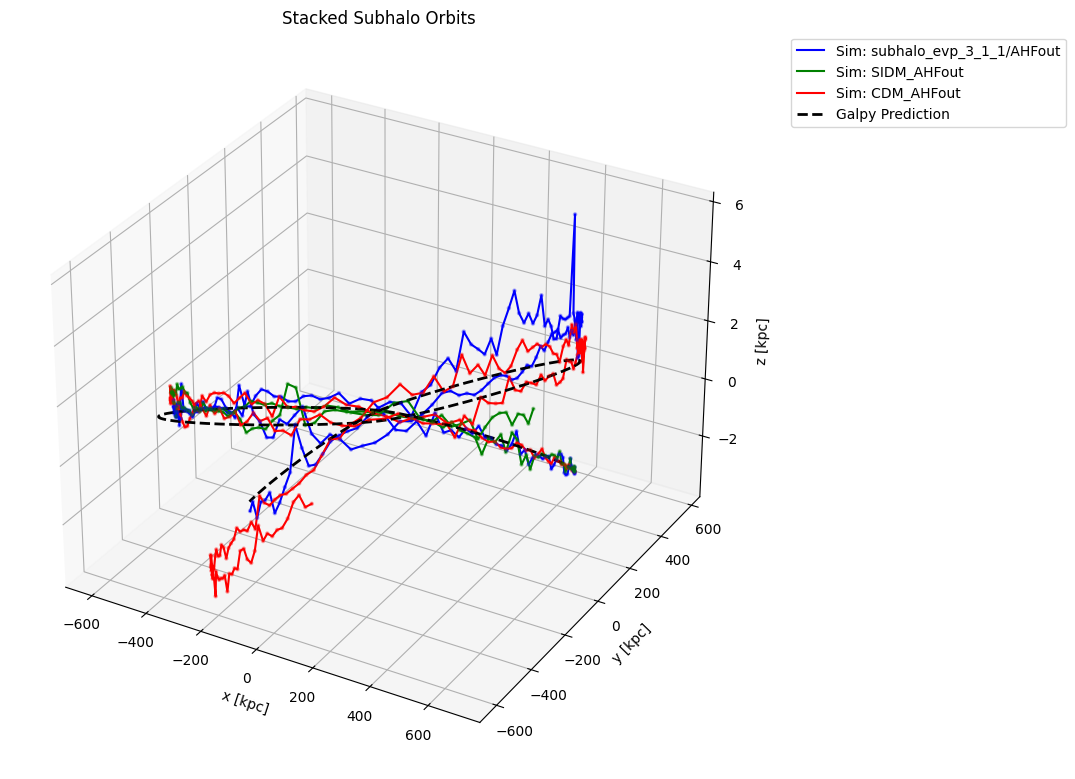

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
from galpy.potential import NFWPotential
from galpy.orbit import Orbit

# ==================== CONFIG & CONSTANTS ====================
BASE_PATH = "./Data/"
# List your folder names here
FOLDERS = ["subhalo_evp_3_1_1/AHFout", "SIDM_AHFout", "CDM_AHFout"] 
TOTAL_SNAPS = 280
HOST_CENTER = np.array([10000.0, 10000.0, 10000.0])

# Galpy Params
RO_KPC, VO_KMS = 1.0, 220.0
T_UNIT_GYR = RO_KPC / (VO_KMS * 1.022712)
POT = NFWPotential(mvir=20.0, conc=6.5, ro=RO_KPC, vo=VO_KMS)

# ==================== HELPER FUNCTION ====================
def read_subhalo_data(folder_name):
    """Reads snapshot data from a specific folder."""
    coords = []
    ahf_dir = os.path.join(BASE_PATH, folder_name)
    
    for i in range(TOTAL_SNAPS + 1):
        path = os.path.join(ahf_dir, f"{i}-halos")
        if not os.path.exists(path): continue
        
        with open(path, 'r') as f:
            lines = f.readlines()
            for line in lines[1:]:
                cols = line.split()
                # Assuming index 1 is hostHalo; adjusting for first subhalo
                pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                coords.append(pos - HOST_CENTER)
                # print(pos)  # Debug: print the last read position
    return np.array(coords)

# ==================== PROCESSING MULTIPLE FOLDERS ====================
all_sims = {}

for folder in FOLDERS:
    print(f"Processing {folder}...")
    data = read_subhalo_data(folder)
    print(data)
    if len(data) > 0:
        all_sims[folder] = data

# ==================== PLOTTING ====================
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Loop through our stored data to plot each one
colors = ["blue", "green", "red"]  

for (name, coords), color in zip(all_sims.items(), colors):
    ax.plot(coords[:,0], coords[:,1], coords[:,2], label=f'Sim: {name}', lw=1.5, color=color)
    ax.scatter(coords[:,0], coords[:,1], coords[:,2], s=5, alpha=0.3, color=color)

# Add your Galpy prediction once for comparison
# (Assuming the initial conditions are roughly the same for the set)
orb = Orbit([0.7*974.4/RO_KPC, 0.0/VO_KMS, 33.15/VO_KMS, 0.0, 0.0, 0.0], ro=RO_KPC, vo=VO_KMS)
t_galpy = np.linspace(0, 14.0/T_UNIT_GYR, 500)
orb.integrate(t_galpy, POT)
ax.plot(orb.x(t_galpy)*RO_KPC, orb.y(t_galpy)*RO_KPC, orb.z(t_galpy)*RO_KPC, 
        'black', label='Galpy Prediction', lw=2, ls='--')

ax.set_title("Stacked Subhalo Orbits")
ax.set_xlabel("x [kpc]"); ax.set_ylabel("y [kpc]"); ax.set_zlabel("z [kpc]")
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

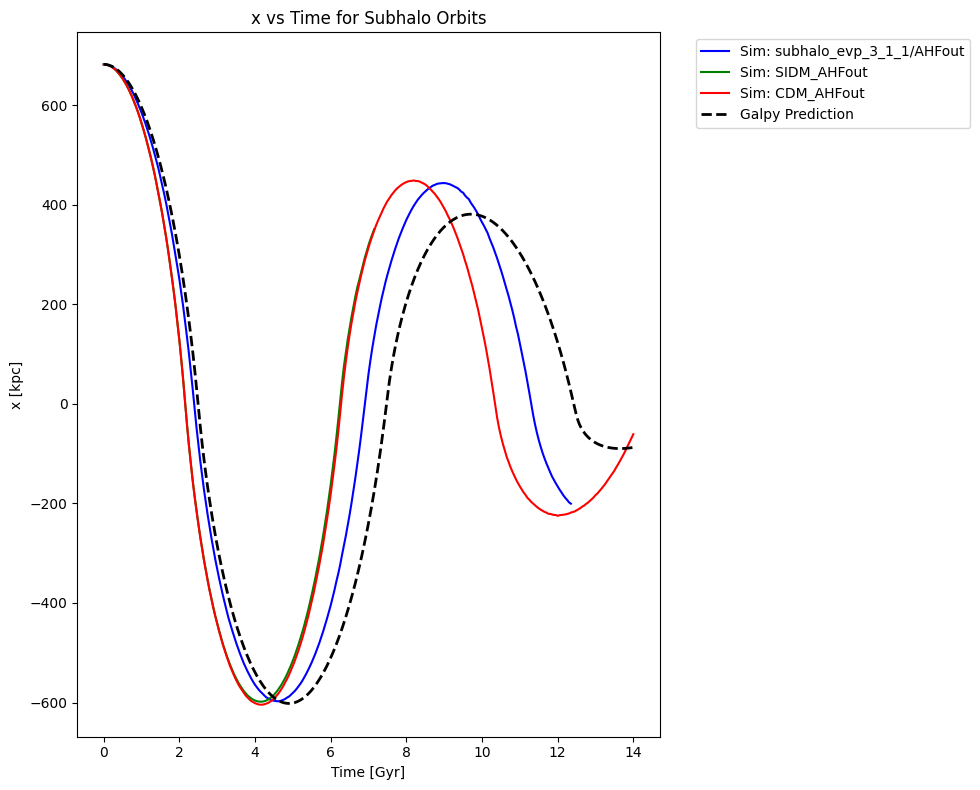

In [13]:
# make plot in x y z versus time 

import matplotlib.pyplot as plt
import numpy as np

# ==================== x versus time ====================
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111)

# Loop through our stored data to plot each one
colors = ["blue", "green", "red"]  

DT_snap = 0.05  # Assuming 0.05 Gyr per snapshot

for (name, coords), color in zip(all_sims.items(), colors):
    time = np.arange(coords.shape[0]) * DT_snap
    ax.plot(time, coords[:,0], label=f'Sim: {name}', lw=1.5, color=color)

# Add your Galpy prediction once for comparison
# (Assuming the initial conditions are roughly the same for the set)
orb = Orbit([0.7*974.4/RO_KPC, 0.0/VO_KMS, 33.15/VO_KMS, 0.0, 0.0, 0.0], ro=RO_KPC, vo=VO_KMS)
t_galpy = np.linspace(0, 14.0/T_UNIT_GYR, 500)
orb.integrate(t_galpy, POT)
galpy_x = orb.x(t_galpy)*RO_KPC
ax.plot(t_galpy*T_UNIT_GYR, galpy_x, 'black', label='Galpy Prediction', lw=2, ls='--')

ax.set_title("x vs Time for Subhalo Orbits")
ax.set_xlabel("Time [Gyr]")
ax.set_ylabel("x [kpc]")
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

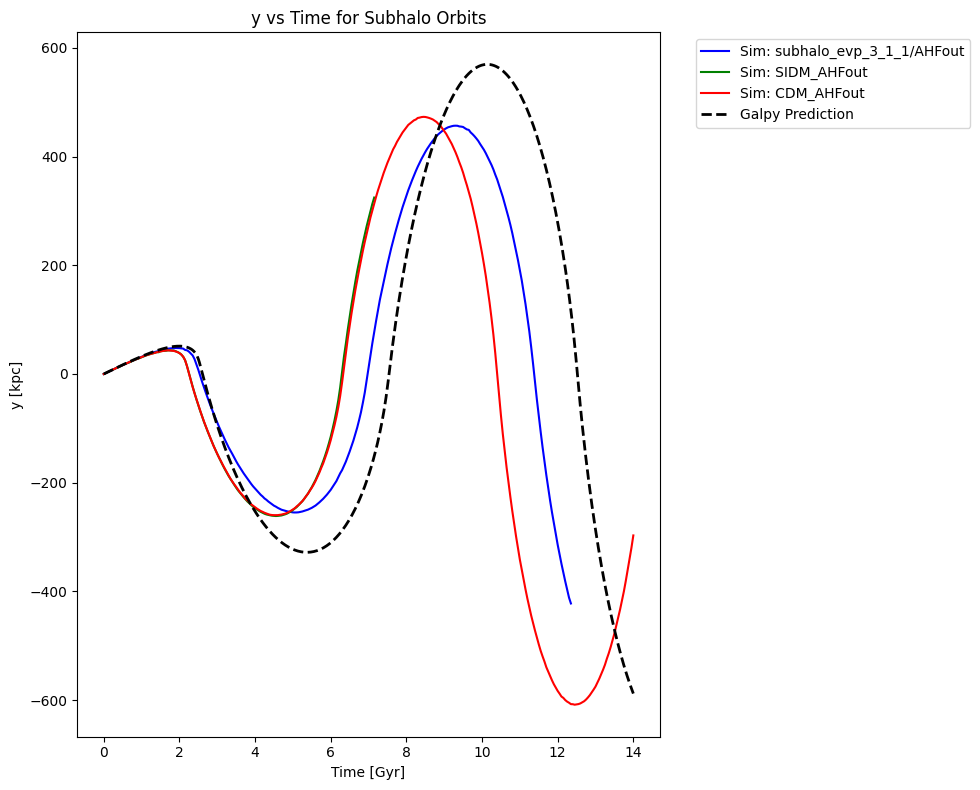

In [14]:
# make plot in x y z versus time 

import matplotlib.pyplot as plt
import numpy as np

# ==================== y versus time ====================
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111)

# Loop through our stored data to plot each one
colors = ["blue", "green", "red"]  

DT_snap = 0.05  # Assuming 0.05 Gyr per snapshot

for (name, coords), color in zip(all_sims.items(), colors):
    time = np.arange(coords.shape[0]) * DT_snap
    ax.plot(time, coords[:,1], label=f'Sim: {name}', lw=1.5, color=color)

# Add your Galpy prediction once for comparison
# (Assuming the initial conditions are roughly the same for the set)
orb = Orbit([0.7*974.4/RO_KPC, 0.0/VO_KMS, 33.15/VO_KMS, 0.0, 0.0, 0.0], ro=RO_KPC, vo=VO_KMS)
t_galpy = np.linspace(0, 14.0/T_UNIT_GYR, 500)
orb.integrate(t_galpy, POT)
galpy_y = orb.y(t_galpy)*RO_KPC
ax.plot(t_galpy*T_UNIT_GYR, galpy_y, 'black', label='Galpy Prediction', lw=2, ls='--')

ax.set_title("y vs Time for Subhalo Orbits")
ax.set_xlabel("Time [Gyr]")
ax.set_ylabel("y [kpc]")
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

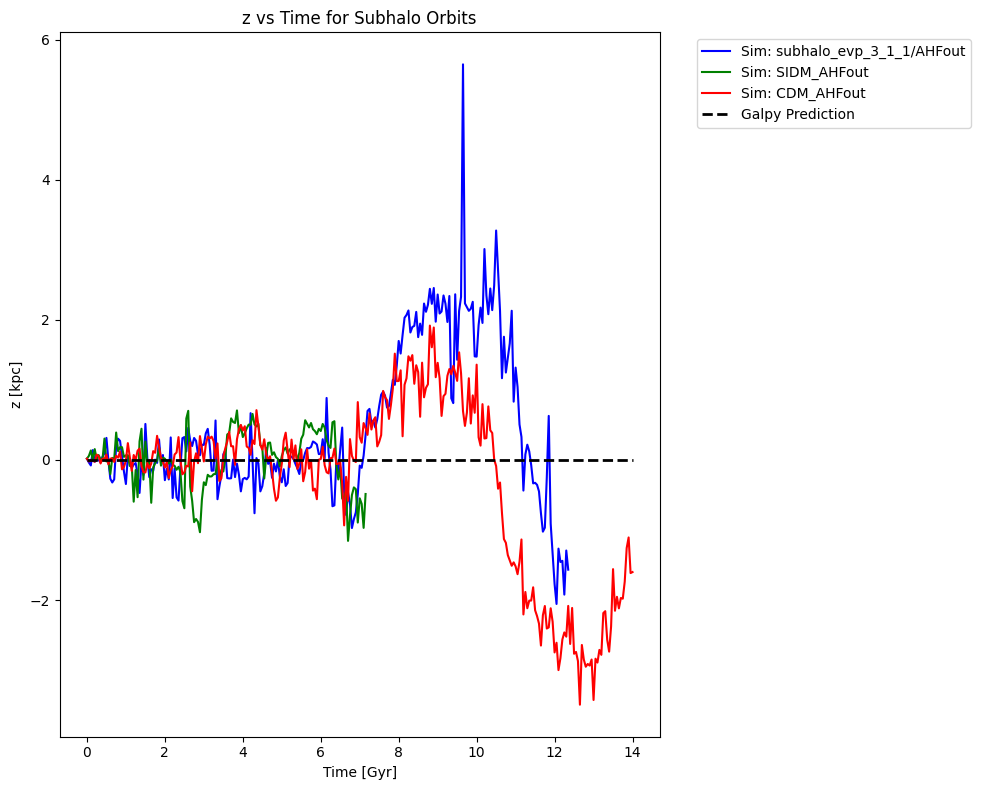

In [15]:
# make plot in x y z versus time 

import matplotlib.pyplot as plt
import numpy as np

# ==================== z versus time ====================
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111)

# Loop through our stored data to plot each one
colors = ["blue", "green", "red"]  

DT_snap = 0.05  # Assuming 0.05 Gyr per snapshot

for (name, coords), color in zip(all_sims.items(), colors):
    time = np.arange(coords.shape[0]) * DT_snap
    ax.plot(time, coords[:,2], label=f'Sim: {name}', lw=1.5, color=color)

# Add your Galpy prediction once for comparison
# (Assuming the initial conditions are roughly the same for the set)
orb = Orbit([0.7*974.4/RO_KPC, 0.0/VO_KMS, 33.15/VO_KMS, 0.0, 0.0, 0.0], ro=RO_KPC, vo=VO_KMS)
t_galpy = np.linspace(0, 14.0/T_UNIT_GYR, 500)
orb.integrate(t_galpy, POT)

galpy_z = orb.z(t_galpy)*RO_KPC
ax.plot(t_galpy*T_UNIT_GYR, galpy_z, 'black', label='Galpy Prediction', lw=2, ls='--')

ax.set_title("z vs Time for Subhalo Orbits")
ax.set_xlabel("Time [Gyr]")
ax.set_ylabel("z [kpc]")
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

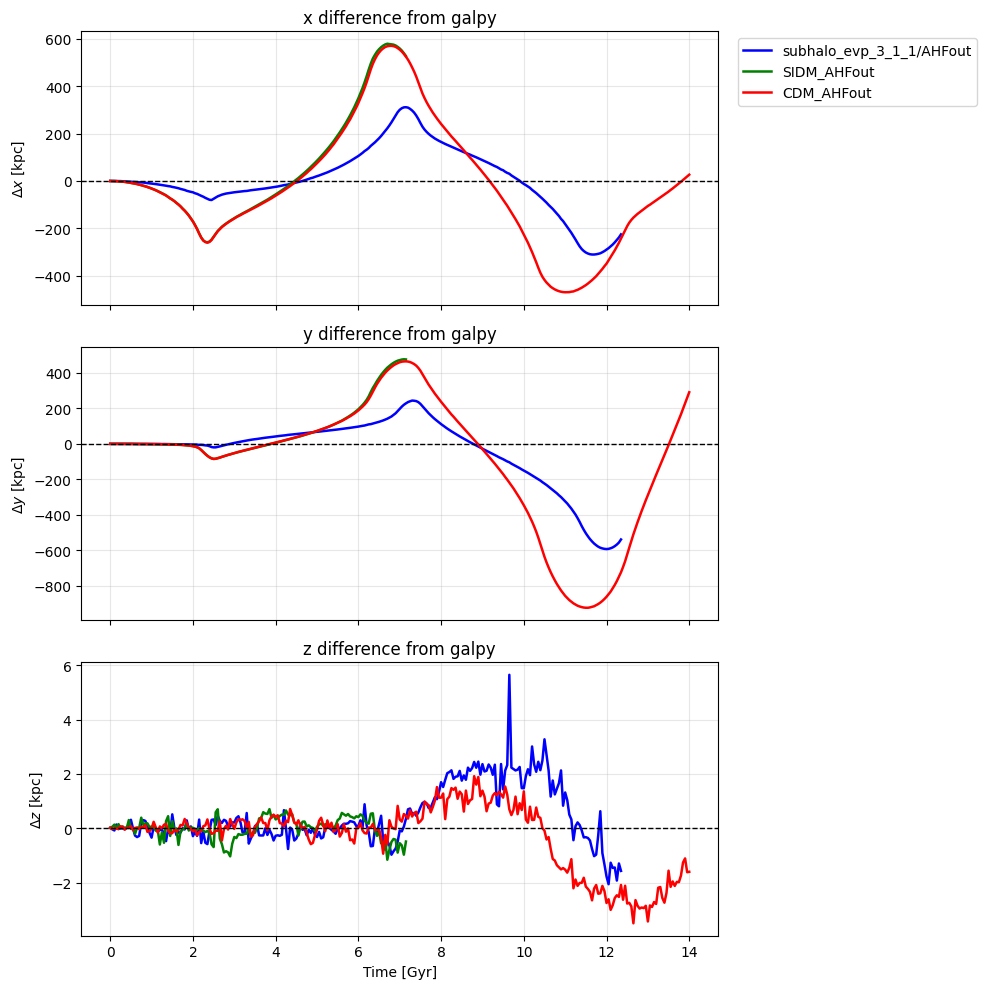

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from galpy.orbit import Orbit

# ==========================================================
# Compare simulation - galpy in x, y, z
# ==========================================================

DT_snap = 0.05  # Gyr per snapshot
colors = ["blue", "green", "red"]

# --- galpy prediction ---
orb = Orbit([0.7*974.4/RO_KPC, 0.0/VO_KMS, 33.15/VO_KMS, 0.0, 0.0, 0.0],
            ro=RO_KPC, vo=VO_KMS)

t_galpy = np.linspace(0, 14.0/T_UNIT_GYR, 500)
orb.integrate(t_galpy, POT)

t_galpy_gyr = t_galpy * T_UNIT_GYR
galpy_x = orb.x(t_galpy) * RO_KPC
galpy_y = orb.y(t_galpy) * RO_KPC
galpy_z = orb.z(t_galpy) * RO_KPC

# --- plotting ---
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

for (name, coords), color in zip(all_sims.items(), colors):
    t_sim = np.arange(coords.shape[0]) * DT_snap

    # interpolate galpy prediction onto simulation times
    galpy_x_on_sim = np.interp(t_sim, t_galpy_gyr, galpy_x)
    galpy_y_on_sim = np.interp(t_sim, t_galpy_gyr, galpy_y)
    galpy_z_on_sim = np.interp(t_sim, t_galpy_gyr, galpy_z)

    dx = coords[:, 0] - galpy_x_on_sim
    dy = coords[:, 1] - galpy_y_on_sim
    dz = coords[:, 2] - galpy_z_on_sim

    axes[0].plot(t_sim, dx, lw=1.8, color=color, label=name)
    axes[1].plot(t_sim, dy, lw=1.8, color=color, label=name)
    axes[2].plot(t_sim, dz, lw=1.8, color=color, label=name)

# formatting
labels = [r"$\Delta x$ [kpc]", r"$\Delta y$ [kpc]", r"$\Delta z$ [kpc]"]
titles = ["x difference from galpy", "y difference from galpy", "z difference from galpy"]

for ax, yl, ttl in zip(axes, labels, titles):
    ax.axhline(0, color="black", ls="--", lw=1)
    ax.set_ylabel(yl)
    ax.set_title(ttl)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time [Gyr]")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))

plt.tight_layout()
plt.show()

CDM shape: (281, 3)
SIDM shape: (144, 3)


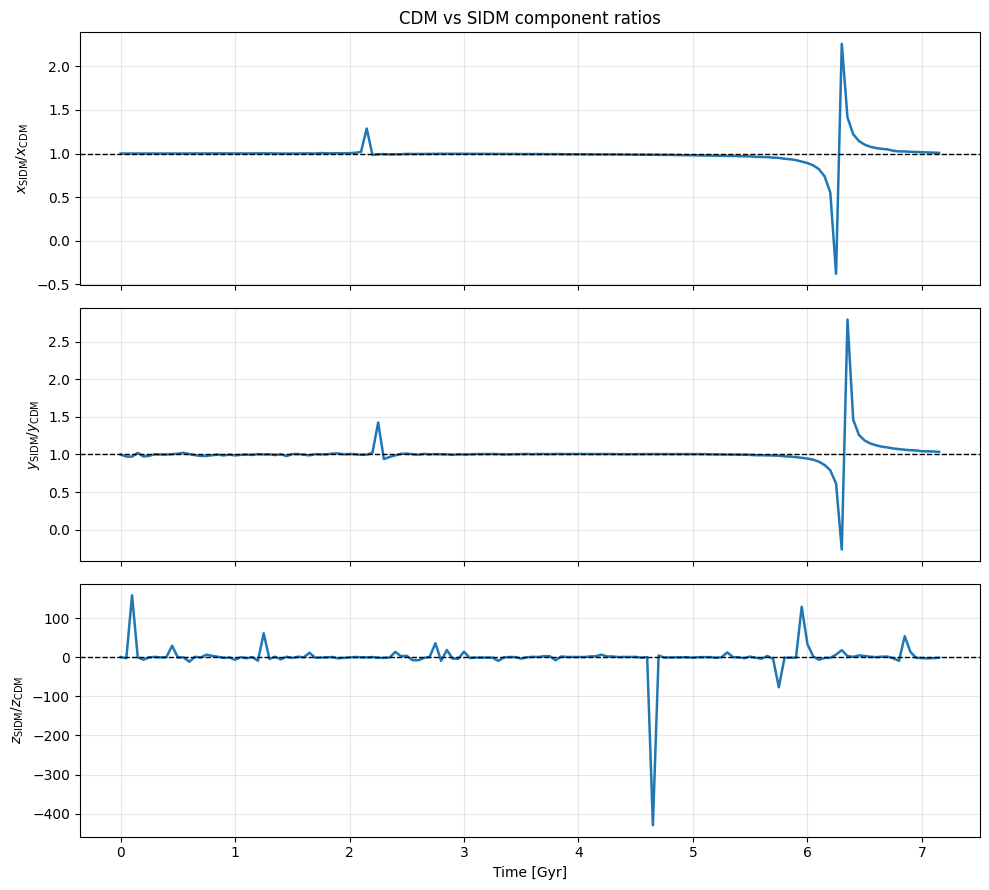

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# Extract CDM and one SIDM run from all_sims
# ----------------------------------------------------------

cdm_coords = None
sidm_coords = None

for name, coords in all_sims.items():
    lname = name.lower()
    
    if "cdm" in lname:
        cdm_coords = coords
    elif "sidm" in lname:
        sidm_coords = coords   # pick the first SIDM you find

# sanity check
if cdm_coords is None:
    raise ValueError("No CDM run found in all_sims")

if sidm_coords is None:
    raise ValueError("No SIDM run found in all_sims")

print("CDM shape:", cdm_coords.shape)
print("SIDM shape:", sidm_coords.shape)

DT_snap = 0.05  # Gyr per snapshot
eps = 1e-6      # avoid divide-by-near-zero problems

# trim to common length if needed
N = min(len(cdm_coords), len(sidm_coords))
cdm = cdm_coords[:N]
sidm = sidm_coords[:N]

t = np.arange(N) * DT_snap

def safe_ratio(num, den, eps=1e-6):
    out = np.full_like(num, np.nan, dtype=float)
    mask = np.abs(den) > eps
    out[mask] = num[mask] / den[mask]
    return out

rx = safe_ratio(sidm[:, 0], cdm[:, 0], eps)
ry = safe_ratio(sidm[:, 1], cdm[:, 1], eps)
rz = safe_ratio(sidm[:, 2], cdm[:, 2], eps)

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(t, rx, lw=1.8)
axes[1].plot(t, ry, lw=1.8)
axes[2].plot(t, rz, lw=1.8)

axes[0].axhline(1.0, color="black", ls="--", lw=1)
axes[1].axhline(1.0, color="black", ls="--", lw=1)
axes[2].axhline(1.0, color="black", ls="--", lw=1)

axes[0].set_ylabel(r"$x_{\rm SIDM}/x_{\rm CDM}$")
axes[1].set_ylabel(r"$y_{\rm SIDM}/y_{\rm CDM}$")
axes[2].set_ylabel(r"$z_{\rm SIDM}/z_{\rm CDM}$")
axes[2].set_xlabel("Time [Gyr]")

axes[0].set_title("CDM vs SIDM component ratios")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()